# Núcleo 2 — Aporte vs. recibo por provincia

Comparo, para cada una de las 24 jurisdicciones, cuánto pesa en la economía nacional
(usando el Producto Bruto Geográfico, PBG, como proxy del aporte) contra cuánto recibe
de la coparticipación federal según los coeficientes de la Ley 23.548. La idea es ver qué
provincias quedan "ganando" o "perdiendo" con un esquema de reparto que no se actualizó
desde 1988, pese a los cambios en el peso económico de cada una.

Fuentes:
- PBG: CEPAL, año 2024 (el más reciente disponible; dato preliminar en la fuente
  original). `data/raw/pbg/Jurisdiccion_52sectores.xlsx`. En rigor es el Valor
  Agregado Bruto a precios básicos, en pesos a precios de 2004; lo llamo PBG por
  simplicidad (ver limitaciones).
- Coeficientes de coparticipación: Ley 23.548, con el valor de CABA corregido a 1,4%
  (régimen automático vigente desde 2020; el documento de 2018 traía 3,75%).
  `data/raw/coeficientes/indices_copa_2018.pdf`. Desde diciembre de 2022, por una
  cautelar de la Corte Suprema, Nación le transfiere a CABA otro 1,55% por fuera de ese
  coeficiente (2,95% en total); lo retomo al final.

El detalle de cómo armé cada columna está en `docs/methodology.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

COLOR_POSITIVO = "#2a78d6"   # recibe más de lo que aporta (proxy PBG)
COLOR_NEGATIVO = "#e34948"   # recibe menos de lo que aporta
COLOR_CORDOBA_BORDE = "#0b0b0b"

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(BASE_DIR / "data" / "processed" / "aporte_vs_recibo.csv")
df

,provincia,pct_pbg_aporte,pct_coparticipacion_recibe,pct_coparticipacion_entre_provincias,diferencia_pp
0,Chaco,0.015133,0.028314,0.048186,3.305284
1,Formosa,0.005220,0.020661,0.035162,2.994227
2,Tucumán,0.018976,0.027002,0.045953,2.697729
3,Santiago del Estero,0.015869,0.023449,0.039907,2.403746
4,Corrientes,0.012674,0.021099,0.035907,2.323231
5,Catamarca,0.006530,0.015633,0.026604,2.007428
6,Entre Ríos,0.027625,0.027713,0.047162,1.953715
7,San Juan,0.013134,0.019186,0.032651,1.951712
8,Misiones,0.012799,0.018748,0.031907,1.910804
9,Salta,0.018856,0.021755,0.037023,1.816669


## 1. Columnas

- `pct_pbg_aporte`: % del PBG de esa provincia sobre la suma de las 24 jurisdicciones
  (2024; la fuente trae además una fila "No distribuido", ~0,06%, que queda afuera).
- `pct_coparticipacion_recibe`: coeficiente de Ley 23.548, es decir, % de la masa
  coparticipable **total**. Los 24 suman ~59%: el resto queda en Nación y en el Fondo
  ATN.
- `pct_coparticipacion_entre_provincias`: el mismo coeficiente dividido por la suma de
  los 24, o sea, % de lo que se reparte **entre provincias**. Suma 100%, igual que el
  PBG, y es la columna que tiene sentido comparar.
- `diferencia_pp`: `pct_coparticipacion_entre_provincias - pct_pbg_aporte`, en puntos
  porcentuales. Positivo = recibe una porción del reparto mayor que su peso en el PBG;
  negativo, lo contrario.

Comparar directamente el coeficiente crudo (que suma ~59%) contra el PBG (que suma 100%)
deja a todas las provincias grandes con brechas negativas solo por su tamaño: Córdoba,
por ejemplo, aparecería con −3,5 pp cuando en realidad su porción del reparto es casi
idéntica a su peso económico.

In [2]:
assert len(df) == 24, "Se esperaban 24 jurisdicciones"
df[["pct_pbg_aporte", "pct_coparticipacion_recibe"]].describe()

,pct_pbg_aporte,pct_coparticipacion_recibe
count,24.000000,24.000000
mean,0.041667,0.024483
std,0.072311,0.024108
min,0.005220,0.007000
25%,0.010445,0.012654
50%,0.014775,0.018967
75%,0.029056,0.024501
max,0.318674,0.124638


## 2. Ranking de las 24 jurisdicciones por diferencia

Ordenadas de mayor "ganadora" (recibe mucho más de lo que aporta) a mayor
"perdedora".

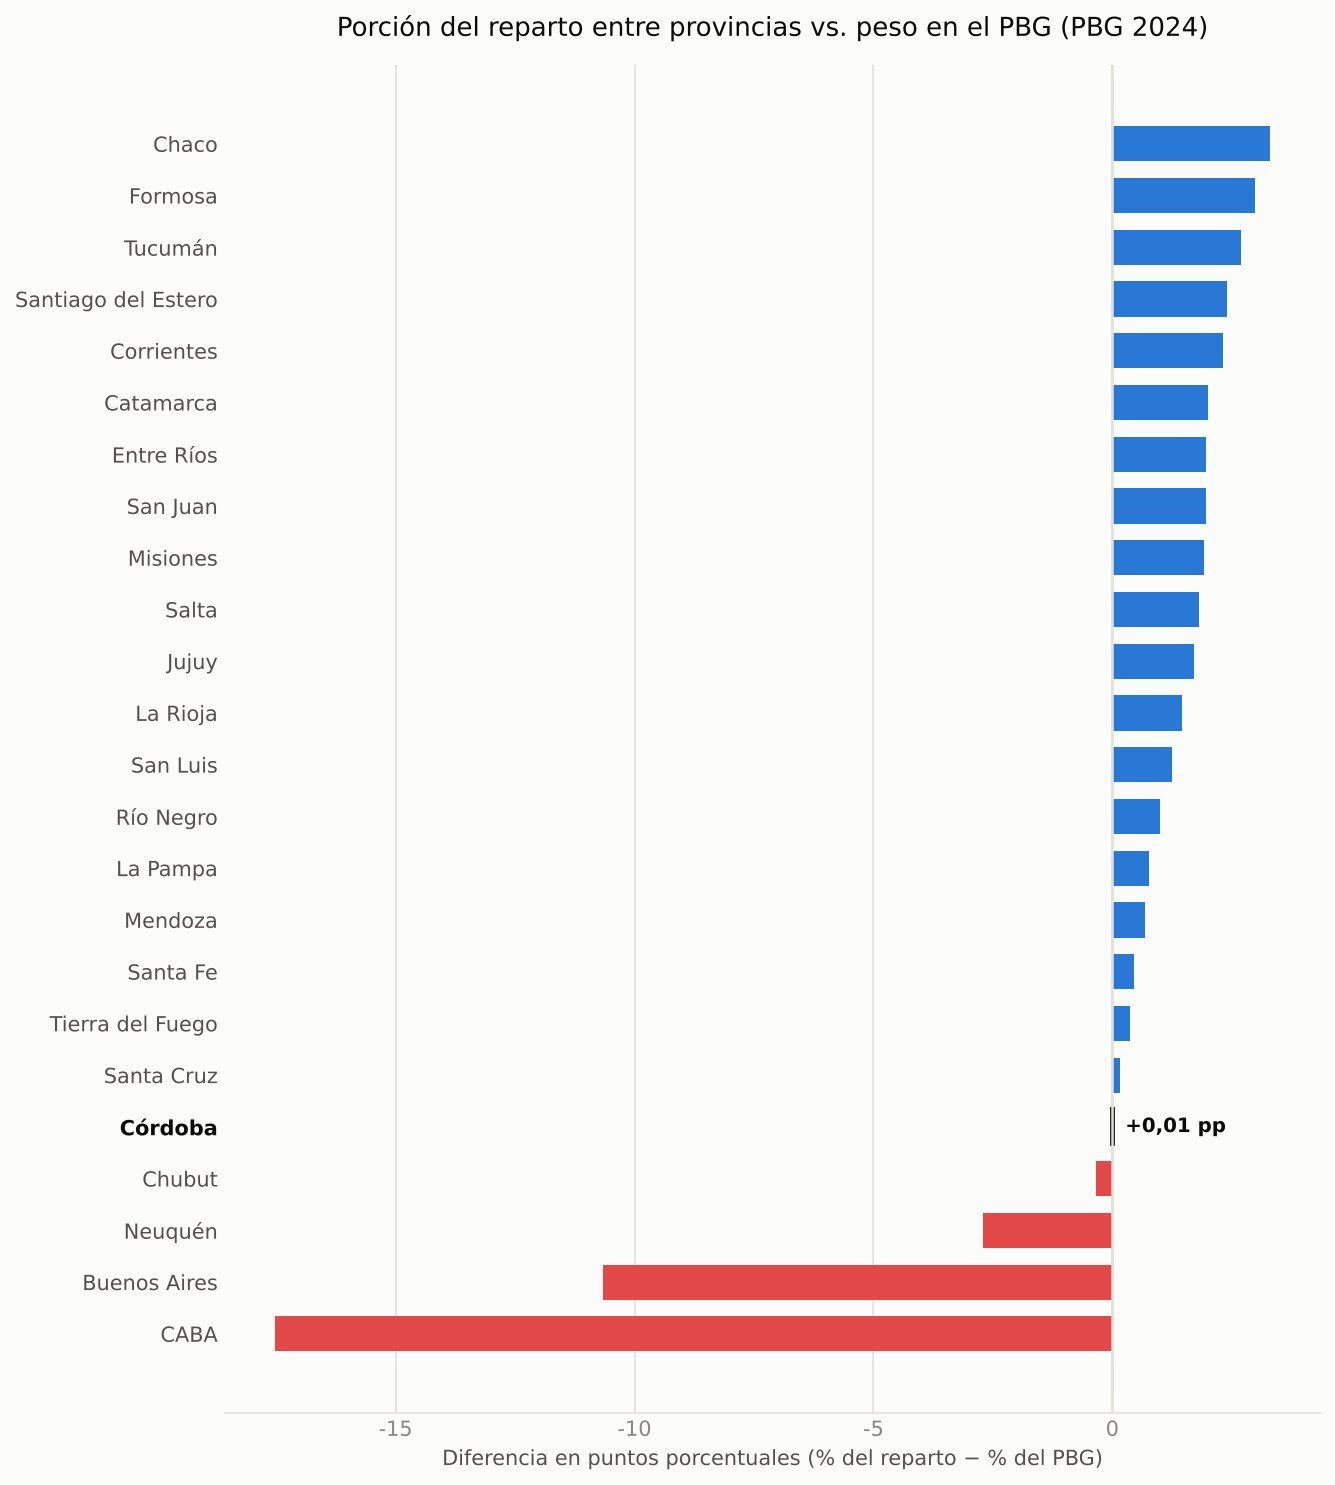

In [3]:
orden = df.sort_values("diferencia_pp", ascending=True).reset_index(drop=True)
colores = [COLOR_POSITIVO if v >= 0 else COLOR_NEGATIVO for v in orden["diferencia_pp"]]
bordes = [COLOR_CORDOBA_BORDE if p == "Córdoba" else "none" for p in orden["provincia"]]
grosor_borde = [1.8 if p == "Córdoba" else 0 for p in orden["provincia"]]

fig, ax = plt.subplots(figsize=(9, 10), dpi=150)
bars = ax.barh(
    orden["provincia"], orden["diferencia_pp"],
    color=colores, edgecolor=bordes, linewidth=grosor_borde, height=0.68,
)

ax.axvline(0, color=GRID_COLOR, linewidth=1.2)
ax.set_title(
    "Porción del reparto entre provincias vs. peso en el PBG (PBG 2024)",
    fontsize=12.5, color=INK_PRIMARY, pad=14,
)
ax.set_xlabel("Diferencia en puntos porcentuales (% del reparto − % del PBG)", fontsize=10)
ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: "0" if abs(x) < 1e-9 else f"{x:+.0f}"))

fila_cba = orden[orden["provincia"] == "Córdoba"].iloc[0]
ax.annotate(
    f"{fila_cba['diferencia_pp']:+.2f} pp".replace(".", ","),
    (max(fila_cba["diferencia_pp"], 0), orden.index[orden["provincia"] == "Córdoba"][0]),
    textcoords="offset points", xytext=(6, 0), va="center", fontsize=9.5,
    color=INK_PRIMARY, fontweight="bold",
)

# Resaltar la etiqueta de Córdoba en el eje y
for label in ax.get_yticklabels():
    if label.get_text() == "Córdoba":
        label.set_fontweight("bold")
        label.set_color(INK_PRIMARY)
    else:
        label.set_color(INK_SECONDARY)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "aporte_vs_recibo_ranking.png", dpi=300, facecolor=SURFACE)
plt.show()

Córdoba recibe el 8,58% de lo que se reparte entre provincias y representa el 8,57% del
PBG nacional: una diferencia de +0,01 puntos porcentuales, prácticamente nula. Con este
proxy, Córdoba recibe casi exactamente en proporción a su peso económico, y lo mismo
pasa, con diferencias chicas, con Santa Fe (+0,5 pp) y Mendoza (+0,7 pp).

Las que quedan claramente por debajo son CABA (−17,5 pp), Buenos Aires (−10,7 pp) y
Neuquén (−2,7 pp). Del otro lado, las que más reciben en relación a su PBG son Chaco
(+3,3 pp), Formosa (+3,0 pp) y Tucumán (+2,7 pp). Es coherente con el objetivo original
del régimen de 1988 de redistribuir hacia las provincias de menor desarrollo relativo, y
con un problema conocido: el coeficiente de Buenos Aires quedó bajo respecto de su peso
económico y poblacional.

Si a CABA se le computa el 2,95% que efectivamente cobra con la cautelar, su porción del
reparto sube a 4,9% y su brecha se achica a −15,0 pp; la de Córdoba pasa a −0,2 pp. No
cambia la lectura.

### Con lo que cada jurisdicción efectivamente recibió en 2025

El ranking de arriba usa el coeficiente legal. El Núcleo 5 muestra que lo que cada
jurisdicción cobró en 2025 se aparta de ese coeficiente casi solo por la compensación
del Consenso Fiscal, que va en un 56% a Buenos Aires. Si en vez del coeficiente uso la
participación efectiva de 2025, la brecha de Buenos Aires baja de −10,7 a −9,2 puntos y
la de Córdoba pasa de +0,01 a −0,3; el resto se mueve menos de 0,15 puntos.

In [4]:
recibido_2025 = pd.read_csv(BASE_DIR / "data" / "processed" / "comparativo_provincias.csv")
efectiva = df.merge(recibido_2025[["provincia", "participacion_2025"]], on="provincia")
efectiva["diferencia_efectiva_pp"] = (efectiva["participacion_2025"] - efectiva["pct_pbg_aporte"]) * 100
efectiva["cambio_pp"] = efectiva["diferencia_efectiva_pp"] - efectiva["diferencia_pp"]
efectiva[["provincia", "diferencia_pp", "diferencia_efectiva_pp", "cambio_pp"]].sort_values(
    "cambio_pp", key=abs, ascending=False
).head(5).round(2)

,provincia,diferencia_pp,diferencia_efectiva_pp,cambio_pp
22,Buenos Aires,-10.66,-9.17,1.49
19,Córdoba,0.01,-0.28,-0.29
6,Entre Ríos,1.95,1.82,-0.13
16,Santa Fe,0.45,0.33,-0.12
9,Salta,1.82,1.93,0.12


## 3. Limitaciones de este análisis

Esto no es una medición directa de cuánto aporta cada provincia a la recaudación
tributaria nacional coparticipable — el PBG es un proxy, y tiene un problema de
atribución geográfica conocido y significativo.

Las grandes empresas suelen tributar donde tienen su sede fiscal, no donde generan la
actividad económica, y muchas con operaciones en todo el país tienen domicilio fiscal en
CABA. Por eso, en las estadísticas de recaudación por jurisdicción, buena parte de lo
que se genera en otras provincias (Córdoba incluida) figura como pagado en CABA. Si en
vez del PBG usara esa recaudación, CABA aparecería aportando todavía más y las
provincias productivas, menos. El PBG está más cerca de dónde se genera la actividad,
pero no mide directamente lo que tributa cada provincia.

El PBG (2024) se compara con el reparto **entre provincias** (coeficientes
renormalizados para sumar 100%), no con la masa coparticipable total. Eso hace las dos
columnas comparables, pero deja afuera una pregunta distinta: cuánto se queda Nación del
total, que no es lo que mide este núcleo.

El PBG de la fuente está a precios constantes de 2004: la participación de cada
provincia en 2024 está calculada con los precios relativos de 2004, no con los de 2024.
En provincias donde cambió mucho el precio de lo que producen respecto del resto (por
ejemplo, las petroleras), la participación a precios corrientes podría ser distinta. La
fuente no trae una serie a precios corrientes, así que no lo puedo cuantificar.

Además, el PBG que uso es de un solo año (2024, preliminar), mientras que el
coeficiente de coparticipación es esencialmente fijo desde 1988. Comparar una foto de
la estructura económica de un año puntual contra un coeficiente que no se mueve en el
tiempo no capta cómo cambió el peso relativo de cada provincia a lo largo de casi 40
años — que es, de hecho, el argumento central de por qué el esquema de 1988 está
desactualizado.

Un análisis más riguroso del aporte tributario real necesitaría datos de recaudación
por jurisdicción de origen económico (no de domicilio fiscal), que no encontré
disponibles de forma pública y desagregada por provincia.